## Exploratory data analysis
- [RDKit](https://www.rdkit.org/)
- [Scikit-fingerprints](https://scikit-fingerprints.readthedocs.io/stable/)

In [29]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [2]:
visco = pd.read_csv('data/Viscoelastic_WLM.csv')

In [41]:
visco.head()

,Source,ID_surfactant1,Type_surfactant1,SMILES_surfactant1,C_surfactant1 (mM),ID_surfactant2,Type_surfactant2,SMILES_surfactant2,C_surfactant2 (mM),ID_additive1,...,ID_additive2,SMILES_additive2,C_additive2 (mM),T [°C],Viscoelasticity,G₀ [Pa],"G""min [Pa]",ω* cr [rad/s],ͳR [s],η₀[Pa∙s]
0,A1,SLES,anionic,CCCCCCCCCCCCOCCOS(=O)(=O)[O-].[Na+],395.0,LED1A,zwitterionic,CCCCCCCCCCCC(=O)NCCCN+(C)C([O-])=O,55.0,NaCl,...,NaN,NaN,NaN,25,0.0,NaN,NaN,NaN,NaN,0.02
1,A1,SLES,anionic,CCCCCCCCCCCCOCCOS(=O)(=O)[O-].[Na+],395.0,LED1A,zwitterionic,CCCCCCCCCCCC(=O)NCCCN+(C)C([O-])=O,55.0,NaCl,...,NaN,NaN,NaN,25,1.0,4.0,2.70,150.0,0.01,0.03
2,A1,SLES,anionic,CCCCCCCCCCCCOCCOS(=O)(=O)[O-].[Na+],395.0,LED1A,zwitterionic,CCCCCCCCCCCC(=O)NCCCN+(C)C([O-])=O,55.0,NaCl,...,NaN,NaN,NaN,25,1.0,4.5,1.20,10.0,0.10,0.45
3,A1,SLES,anionic,CCCCCCCCCCCCOCCOS(=O)(=O)[O-].[Na+],395.0,LED1A,zwitterionic,CCCCCCCCCCCC(=O)NCCCN+(C)C([O-])=O,55.0,NaCl,...,NaN,NaN,NaN,25,1.0,5.0,0.50,0.8,1.25,6.25
4,A1,SLES,anionic,CCCCCCCCCCCCOCCOS(=O)(=O)[O-].[Na+],395.0,LED1A,zwitterionic,CCCCCCCCCCCC(=O)NCCCN+(C)C([O-])=O,55.0,NaCl,...,NaN,NaN,NaN,25,1.0,4.2,0.35,1.5,0.67,2.80


In [4]:
visco.info()

<class 'pandas.DataFrame'>
RangeIndex: 8395 entries, 0 to 8394
Data columns (total 22 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Source              8395 non-null   str    
 1   ID_surfactant1      8395 non-null   str    
 2   Type_surfactant1    8395 non-null   str    
 3   SMILES_surfactant1  8395 non-null   str    
 4   C_surfactant1 (mM)  8395 non-null   float64
 5   ID_surfactant2      2845 non-null   str    
 6   Type_surfactant2    2845 non-null   str    
 7   SMILES_surfactant2  2750 non-null   str    
 8   C_surfactant2 (mM)  2845 non-null   float64
 9   ID_additive1        5658 non-null   str    
 10  SMILES_additive1    5658 non-null   str    
 11  C_additive1 (mM)    5747 non-null   float64
 12  ID_additive2        1310 non-null   str    
 13  SMILES_additive2    1139 non-null   str    
 14  C_additive2 (mM)    1419 non-null   float64
 15  T [°C]              8395 non-null   int64  
 16  Viscoelasticity  

## Displaying a molecule model

In [5]:
loc = 0

In [6]:
import random

loc = random.randint(0, len(visco) - 1)
print(loc)

6732


In [7]:
smiles = visco['SMILES_surfactant1'].loc[loc]
smiles

'CCCCCCCCCCCC(=O)NC(CCC(=O)O)C(=O)[O-].OCC[NH+](CCO)CCO'

In [8]:
smiles = 'CCCCCCCCCCCC(=O)NCCC[N+](C)C([O-])=O'

In [9]:
from rdkit import Chem
from rdkit.Chem import AllChem
import py3Dmol

# 1. Define the molecule using SMILES
#smiles = "CCO"

mol = Chem.MolFromSmiles(smiles)

if mol is None:
    raise ValueError("Invalid SMILES string")

# 2. Add explicit hydrogen atoms
mol = Chem.AddHs(mol)

# 3. Generate 3D coordinates
params = AllChem.ETKDGv3()
params.randomSeed = 42

result = AllChem.EmbedMolecule(mol, params)

if result != 0:
    raise RuntimeError("Could not generate 3D coordinates")

# 4. Optimize the geometry
AllChem.MMFFOptimizeMolecule(mol)

# 5. Convert to a format understood by the viewer
mol_block = Chem.MolToMolBlock(mol)

# 6. Display interactively
viewer = py3Dmol.view(width=600, height=450)
viewer.addModel(mol_block, "mol")
viewer.setStyle({"stick": {}, "sphere": {"scale": 0.25}})
viewer.zoomTo()
viewer.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

## Compounds with a typo in SMILES

In [10]:
def validate_smiles(smiles):
    if pd.isna(smiles) or not str(smiles):
        return True
    mol = Chem.MolFromSmiles(str(smiles))
    if mol is None:
        return False
    return True

In [14]:
smiles = list(visco['SMILES_surfactant1'].unique())
smiles.extend(visco['SMILES_surfactant2'].unique())
smiles.extend(visco['SMILES_additive1'].unique())
smiles.extend(visco['SMILES_additive2'].unique())
len(smiles)

166

In [15]:
for smile in smiles:
    if not validate_smiles(smile):
        print(smile)

CCCCCCCCCCCCCCCCOCC(O)CN+(C)C.[Br-]
CCCCCCCCCCCCCCCCN+(C)C.[Cl-]
CCCCCCCCCCCCCCCCN+(C)C.[Br-]
CCCCCC1C(CCCCCC(=O)NCCCN(C)(C)CC(=O)[O-])C(C=CC1CCCCCC)CCCCCC(=O)NCCCN(C)(C)CC(=O)[O-]
CCCCCCCCCCCC(=O)NCCCN+(C)C([O-])=O
CCCCCCCCCCCC(=O)NCCCN+(C)(C)CC([O-])=O
[Al+3].[O-]N+[O-].[O-]N+[O-].[O-]N+[O-]
[Na+].[O-]N+[O-]


[12:30:32] SMILES Parse Error: syntax error while parsing: CCCCCCCCCCCCCCCCOCC(O)CN+(C)C.[Br-]
[12:30:32] SMILES Parse Error: check for mistakes around position 25:
[12:30:32] CCCCCCCCCCCCOCC(O)CN+(C)C.[Br-]
[12:30:32] ~~~~~~~~~~~~~~~~~~~~^
[12:30:32] SMILES Parse Error: Failed parsing SMILES 'CCCCCCCCCCCCCCCCOCC(O)CN+(C)C.[Br-]' for input: 'CCCCCCCCCCCCCCCCOCC(O)CN+(C)C.[Br-]'
[12:30:32] SMILES Parse Error: syntax error while parsing: CCCCCCCCCCCCCCCCN+(C)C.[Cl-]
[12:30:32] SMILES Parse Error: check for mistakes around position 18:
[12:30:32] CCCCCCCCCCCCCCCCN+(C)C.[Cl-]
[12:30:32] ~~~~~~~~~~~~~~~~~^
[12:30:32] SMILES Parse Error: Failed parsing SMILES 'CCCCCCCCCCCCCCCCN+(C)C.[Cl-]' for input: 'CCCCCCCCCCCCCCCCN+(C)C.[Cl-]'
[12:30:32] SMILES Parse Error: syntax error while parsing: CCCCCCCCCCCCCCCCN+(C)C.[Br-]
[12:30:32] SMILES Parse Error: check for mistakes around position 18:
[12:30:32] CCCCCCCCCCCCCCCCN+(C)C.[Br-]
[12:30:32] ~~~~~~~~~~~~~~~~~^
[12:30:32] SMILES Parse Error: Failed

### Correcting N+ ion notation

In [16]:
validate_smiles('CCCCCC1C(CCCCCC(=O)NCCCN(C)(C)CC(=O)[O-])C(C=CC1CCCCCC)CCCCCC(=O)NCCCN(C)(C)CC(=O)[O-]')

[12:31:55] Explicit valence for atom # 18 N, 4, is greater than permitted


False

In [38]:
visco[visco['SMILES_surfactant1'] == 'CCCCCC1C(CCCCCC(=O)NCCCN(C)(C)CC(=O)[O-])C(C=CC1CCCCCC)CCCCCC(=O)NCCCN(C)(C)CC(=O)[O-]']

,Source,ID_surfactant1,Type_surfactant1,SMILES_surfactant1,C_surfactant1 (mM),ID_surfactant2,Type_surfactant2,SMILES_surfactant2,C_surfactant2 (mM),ID_additive1,...,ID_additive2,SMILES_additive2,C_additive2 (mM),T [°C],Viscoelasticity,G₀ [Pa],"G""min [Pa]",ω* cr [rad/s],ͳR [s],η₀[Pa∙s]
937,A22,DAB,zwitterionic,CCCCCC1C(CCCCCC(=O)NCCCN(C)(C)CC(=O)[O-])C(C=C...,20.0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,20,0.0,NaN,NaN,NaN,NaN,0.8
938,A22,DAB,zwitterionic,CCCCCC1C(CCCCCC(=O)NCCCN(C)(C)CC(=O)[O-])C(C=C...,30.0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,20,0.0,NaN,NaN,NaN,NaN,5.0
939,A22,DAB,zwitterionic,CCCCCC1C(CCCCCC(=O)NCCCN(C)(C)CC(=O)[O-])C(C=C...,40.0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,20,1.0,1.7,2.000,0.052,19.23,23.0
940,A22,DAB,zwitterionic,CCCCCC1C(CCCCCC(=O)NCCCN(C)(C)CC(=O)[O-])C(C=C...,50.0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,20,1.0,6.0,2.100,0.027,37.04,150.0
941,A22,DAB,zwitterionic,CCCCCC1C(CCCCCC(=O)NCCCN(C)(C)CC(=O)[O-])C(C=C...,60.0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,20,1.0,9.5,2.484,0.011,90.91,550.0
942,A22,DAB,zwitterionic,CCCCCC1C(CCCCCC(=O)NCCCN(C)(C)CC(=O)[O-])C(C=C...,80.0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,20,1.0,16.0,2.080,0.009,111.11,1300.0
943,A22,DAB,zwitterionic,CCCCCC1C(CCCCCC(=O)NCCCN(C)(C)CC(=O)[O-])C(C=C...,100.0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,20,1.0,30.0,2.640,0.004,250.00,5500.0
944,A22,DAB,zwitterionic,CCCCCC1C(CCCCCC(=O)NCCCN(C)(C)CC(=O)[O-])C(C=C...,150.0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,20,1.0,75.0,3.000,0.002,500.00,30000.0
945,A22,DAB,zwitterionic,CCCCCC1C(CCCCCC(=O)NCCCN(C)(C)CC(=O)[O-])C(C=C...,50.0,NaN,NaN,NaN,NaN,NaCl,...,NaN,NaN,NaN,20,1.0,23.0,1.725,0.019,52.63,740.0
946,A22,DAB,zwitterionic,CCCCCC1C(CCCCCC(=O)NCCCN(C)(C)CC(=O)[O-])C(C=C...,50.0,NaN,NaN,NaN,NaN,NaCl,...,NaN,NaN,NaN,20,1.0,24.0,2.064,0.016,62.50,850.0


## Additives

In [27]:
additives = list(visco['SMILES_additive1'].unique())
additives.extend(visco['SMILES_additive2'].unique())
additives

['[Na+].[Cl-]',
 nan,
 'CC1=CC=C(C=C1)S(=O)(=O)[O-].[Na+]',
 'C1=CC=C(C(=C1)C(=O)[O-])O.[Na+]',
 '[Al+3].[O-]N+[O-].[O-]N+[O-].[O-]N+[O-]',
 'O=C([O-])C1=CC=CC=C1O.[Na+]',
 '[Na+].[O-]Cl(=O)=O',
 '[Na+].[O-]N+[O-]',
 '[K+].[Br-]',
 '[Na+].O=C([O-])c1ccccc1O',
 '[Al+3].[Cl-].[Cl-].[Cl-]',
 '[Ca+2].[Cl-].[Cl-]',
 '[Mg+2].[Cl-].[Cl-]',
 '[K+].[Cl-]',
 'Cc1ccc(S(=O)(=O)[O-])cc1.[Na+]',
 '[Na+].[Na+].[O-]C(=O)[O-]',
 '[K+].[K+].[O-]C(=O)[O-]',
 '[Na+].[Br-]',
 '[Na+].[I-]',
 '[Na+].[Na+].[O-]S(=O)(=O)[O-]',
 '[Li+].[Cl-]',
 'O=C(O)c1ccccc1C(=O)O',
 '[Na+].O=C([O-])Cc1ccccc1Nc1c(Cl)cccc1Cl',
 '[La+3].[Cl-].[Cl-].[Cl-]',
 'Cc1ccc([NH3+])cc1.[Cl-]',
 'Oc1ccccc1',
 'O=C([O-])/C=C/c1ccccc1.[Na+]',
 'O=C([O-])/C=C/c1ccccc1O.[Na+]',
 'O=C([O-])/C=C/c1ccccc1OC.[Na+]',
 'O=C([O-])c1ccccc1.[Na+]',
 'O=C([O-])c1ccccc1OC.[Na+]',
 'CC[NH+](CC)CC.[Cl-]',
 'CC[N+](CC)(CC)CC.[Br-]',
 'CCCC[N+](CCCC)(CCCC)CCCC.[Br-]',
 'OCCN(CCO)CCO',
 'NC=O',
 'OCC(O)CO',
 'O=C([O-])c1ccccc1O.[Na+]',
 'NCCCC[C@H](N)C(=O)O'

## Rheological measurements plotting

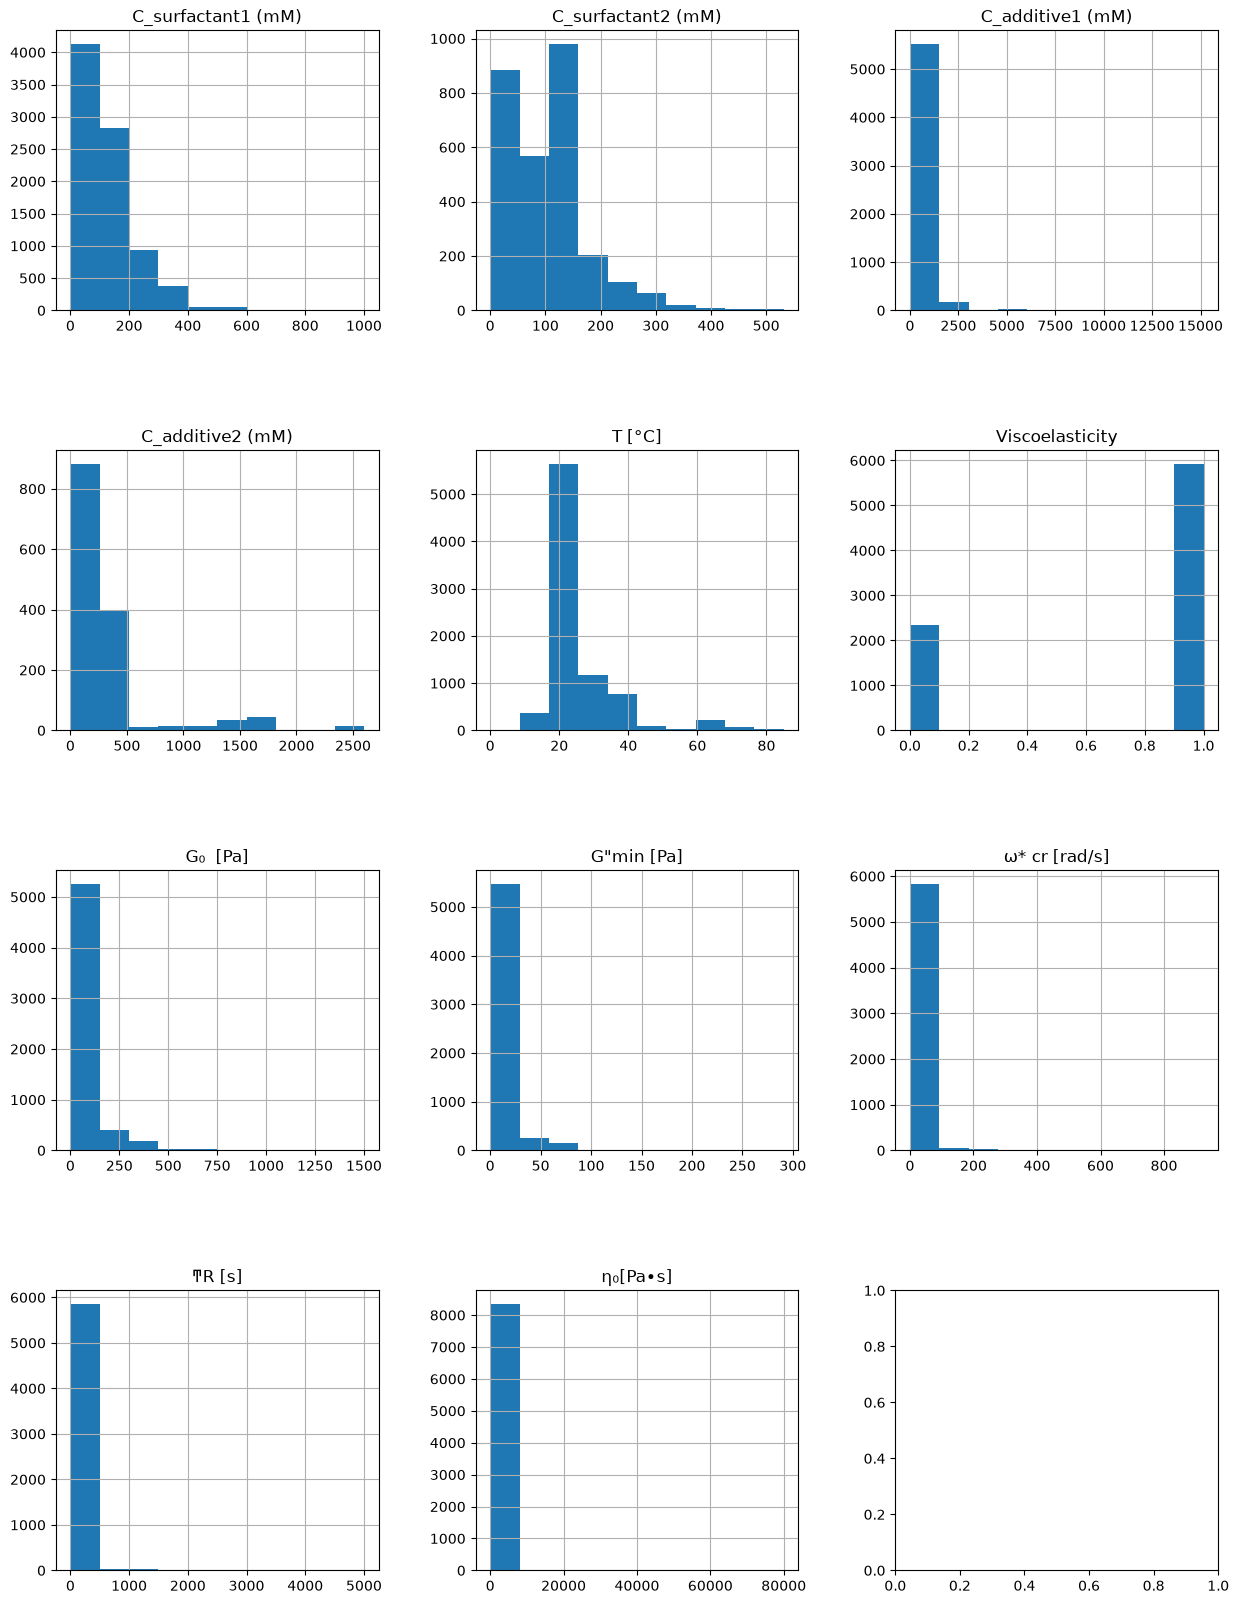

In [98]:
fig, axes = plt.subplots(4, 3, figsize=(15, 20))
axes = axes.flatten()

plt.subplots_adjust(wspace=0.3, hspace=0.5)

ax_index = 0

for column in visco.columns:
    if visco[column].dtype not in ('str', 'bool'):
        visco[column].hist(ax=axes[ax_index], bins=10)
        axes[ax_index].set_title(column)
        ax_index += 1

plt.show()


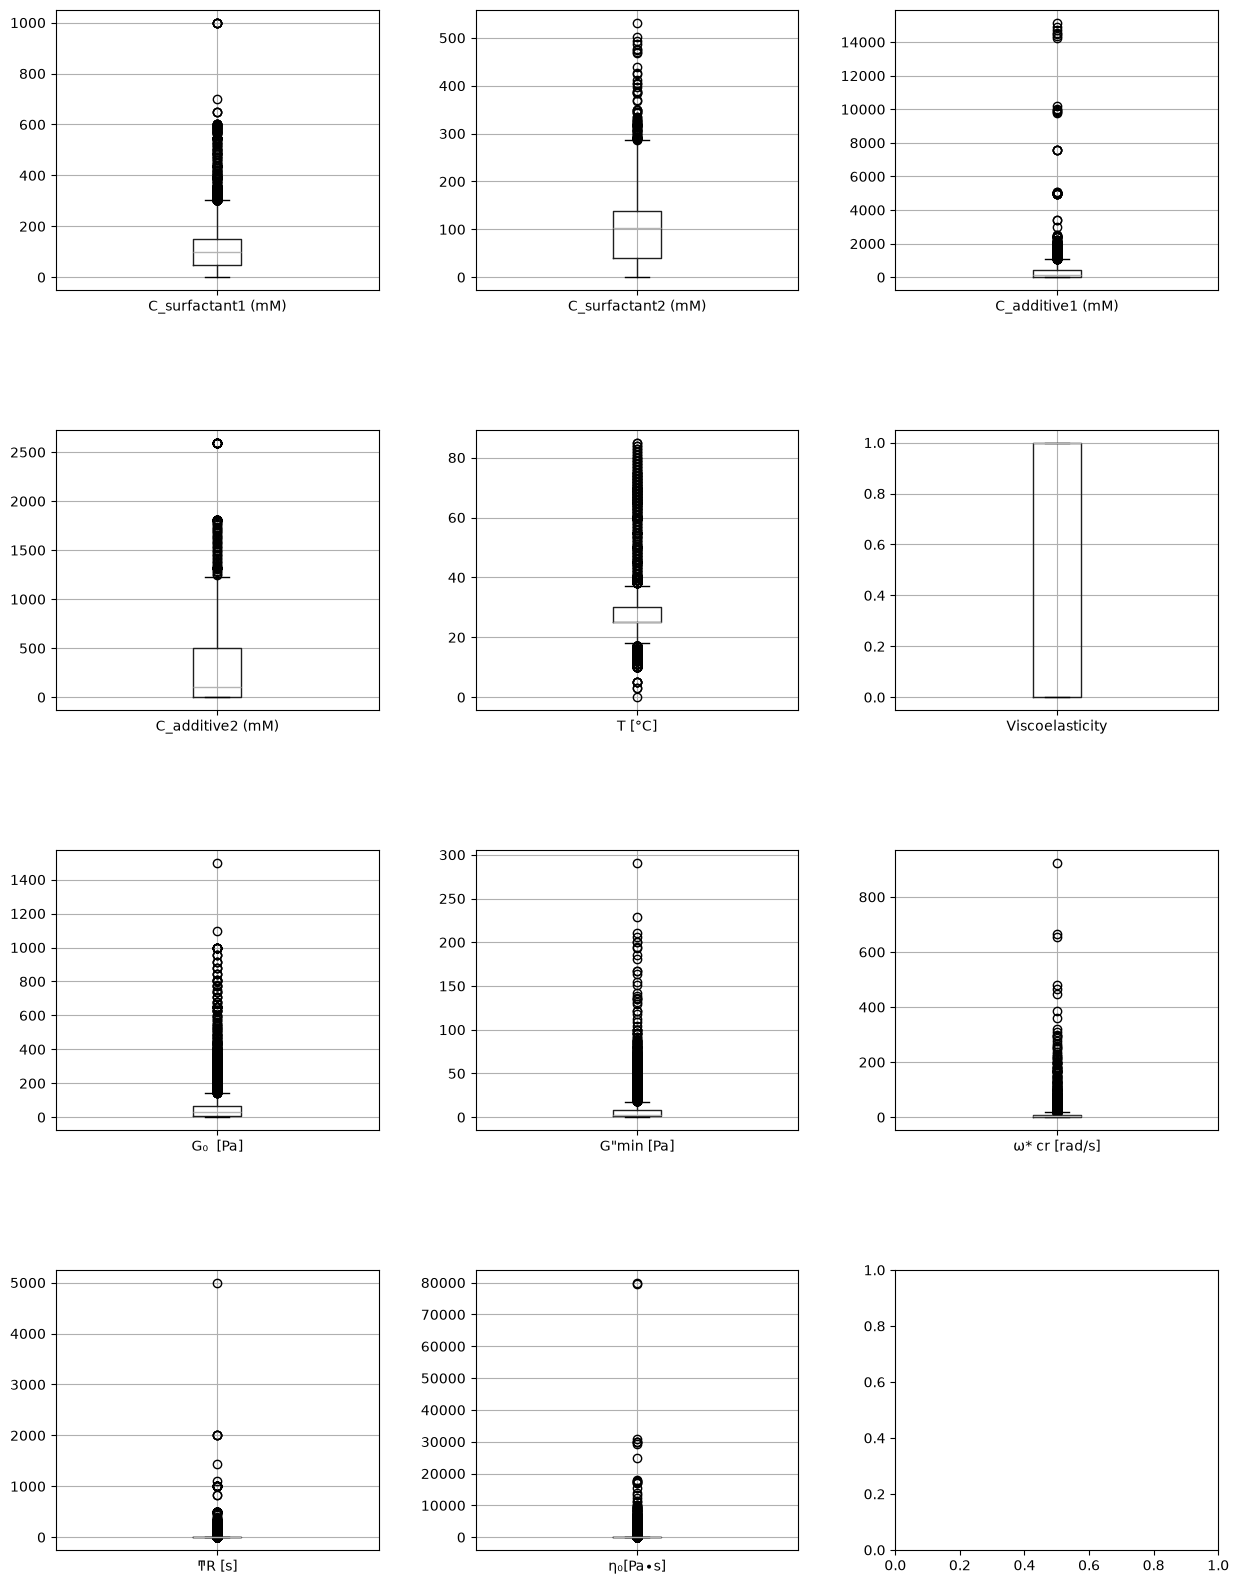

In [103]:
columns = []
for column in visco.columns:
    if visco[column].dtype not in ('str', 'bool'):
        columns.append(column)

fig, axes = plt.subplots(4, 3, figsize=(15, 20))
axes = axes.flatten()

plt.subplots_adjust(wspace=0.3, hspace=0.5)

for ax, col in zip(axes, columns):
    visco.boxplot(column=col, ax=ax)